# Introduction

In this notebook, we will walk through a complete Machine Learning workflow using the Boston Housing dataset. We will cover data collection, preprocessing, feature engineering, model training, evaluation, and deployment. The goal is to build a linear regression model to predict the median value of owner-occupied homes (MEDV) in Boston suburbs. We will also create a FastAPI application to serve our model and make predictions based on input features.

### Understanding the Target Variable

The target variable we aim to predict is **MEDV** (Median value of owner-occupied homes in $1000s). This variable represents the central tendency of home prices in various Boston suburbs and is a crucial indicator of economic status and housing affordability. Predicting MEDV accurately can provide valuable insights for real estate pricing, urban planning, and economic analysis.

### What is Linear Regression?

Linear regression is a statistical method used to model the relationship between a dependent variable (target) and one or more independent variables (features). The goal of linear regression is to find the best-fitting line (linear relationship) that describes how the target variable changes as the feature variables change.

### Linear Regression in this Context

In the context of the Boston Housing dataset, linear regression will help us understand how various factors such as crime rate, number of rooms, property tax rate, and other features influence the median value of homes. By analyzing the coefficients of the linear regression model, we can also gain insights into which features have the most significant impact on home prices.

The linear regression model will allow us to:
- Predict the median value of homes based on the given features.
- Understand the relationships between different features and home prices.
- Make data-driven decisions for real estate investments, urban development, and policy-making.

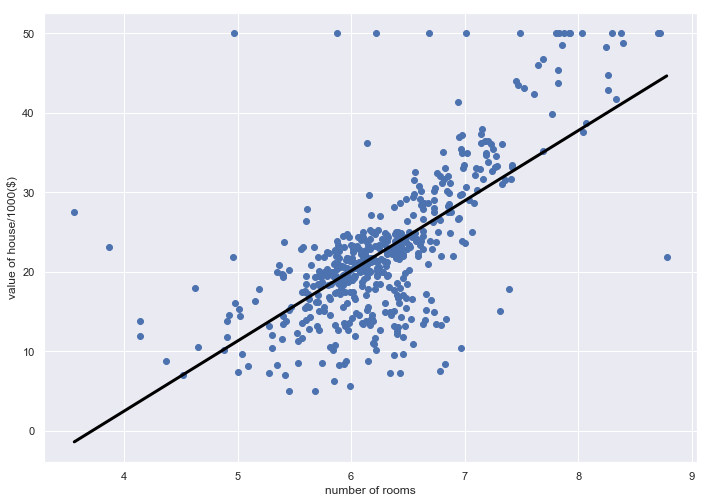


By following this comprehensive workflow, we aim to build a robust model and deploy it using FastAPI to make real-time predictions accessible and actionable.

# Step 1: Importing Libraries
In this step, you will import all the necessary libraries for data manipulation, machine learning, and API development.

We propose the following, but feel free to experiment with other

In [2]:
import pandas as pd  # For data manipulation
from sklearn.model_selection import train_test_split, cross_val_score  # For splitting data and cross-validation
from sklearn.linear_model import LinearRegression  # For linear regression model
from sklearn.preprocessing import MinMaxScaler  # For normalizing data
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # For model evaluation metrics
import pickle  # For serializing the model
import numpy as np  # For numerical operations
import matplotlib.pyplot as plt  # For visualization

# Step 2: Data Collection
You will download the Boston Housing dataset from a specified URL and load it into a Pandas DataFrame.

These are the columns that it includes:

| Feature  | Description                                                      |
|----------|------------------------------------------------------------------|
| CRIM     | per capita crime rate by town                                    |
| ZN       | proportion of residential land zoned for lots over 25,000 sq.ft. |
| INDUS    | proportion of non-retail business acres per town                 |
| CHAS     | Charles River dummy variable (= 1 if tract bounds river; 0 otherwise) |
| NOX      | nitric oxides concentration (parts per 10 million)               |
| RM       | average number of rooms per dwelling                             |
| AGE      | proportion of owner-occupied units built prior to 1940           |
| DIS      | weighted distances to five Boston employment centres             |
| RAD      | index of accessibility to radial highways                        |
| TAX      | full-value property-tax rate per 10,000 USD                      |
| PTRATIO  | pupil-teacher ratio by town                                      |
| B        | 1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town   |
| LSTAT    | % lower status of the population                                 |
| MEDV     | Median value of owner-occupied homes (in 1000 USD)               |

In [3]:
# URL to the Boston Housing dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/housing/housing.data"

# Column names for the dataset
column_names = [
    "CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM",
    "AGE", "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"
]

# your code here...
# Primero vemos una muestra de los datos para saber la separación
import requests

response = requests.get(url)
print(response.text.splitlines()[:5])  # Muestra las primeras 5 líneas

# ahora si leemos el dataset sabiendo que son espacios
df = pd.read_csv(url, delim_whitespace=True, names=column_names)

#Borramos la columna B por que es racista
df = df.drop(columns=["B"])

[' 0.00632  18.00   2.310  0  0.5380  6.5750  65.20  4.0900   1  296.0  15.30 396.90   4.98  24.00', ' 0.02731   0.00   7.070  0  0.4690  6.4210  78.90  4.9671   2  242.0  17.80 396.90   9.14  21.60', ' 0.02729   0.00   7.070  0  0.4690  7.1850  61.10  4.9671   2  242.0  17.80 392.83   4.03  34.70', ' 0.03237   0.00   2.180  0  0.4580  6.9980  45.80  6.0622   3  222.0  18.70 394.63   2.94  33.40', ' 0.06905   0.00   2.180  0  0.4580  7.1470  54.20  6.0622   3  222.0  18.70 396.90   5.33  36.20']


/tmp/ipykernel_28950/1792860163.py:18: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True, names=column_names)


# Step 3: Basic EDA (Exploratory Data Analysis)
Conduct basic EDA to understand the data distribution and relationships between features.

## Histograms
Visualize the distribution of key features using histograms.

In [4]:
df.info() # Información del DataFrame
print(df.describe())  # Estadísticas descriptivas del DataFrame
print(df['ZN'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  LSTAT    506 non-null    float64
 12  MEDV     506 non-null    float64
dtypes: float64(11), int64(2)
memory usage: 51.5 KB
             CRIM          ZN       INDUS        CHAS         NOX          RM  \
count  506.000000  506.000000  506.000000  506.000000  506.000000  506.000000   
mean     3.613524   11.363636   11.136779    0.069170    0.554695    6.284634   
std      8.601545   23.322453 

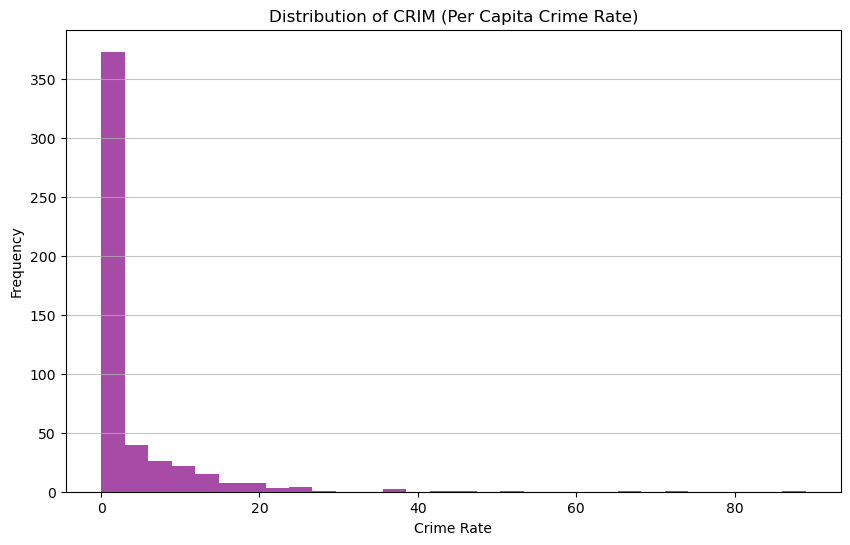

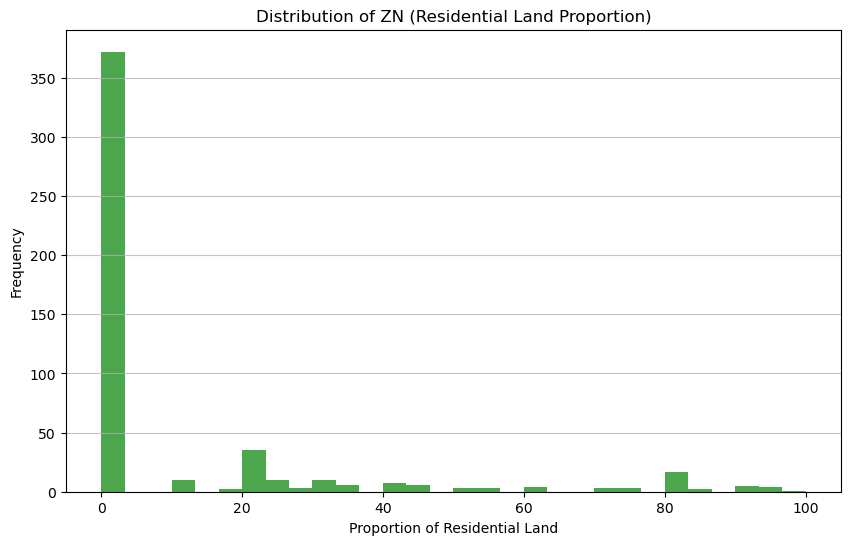

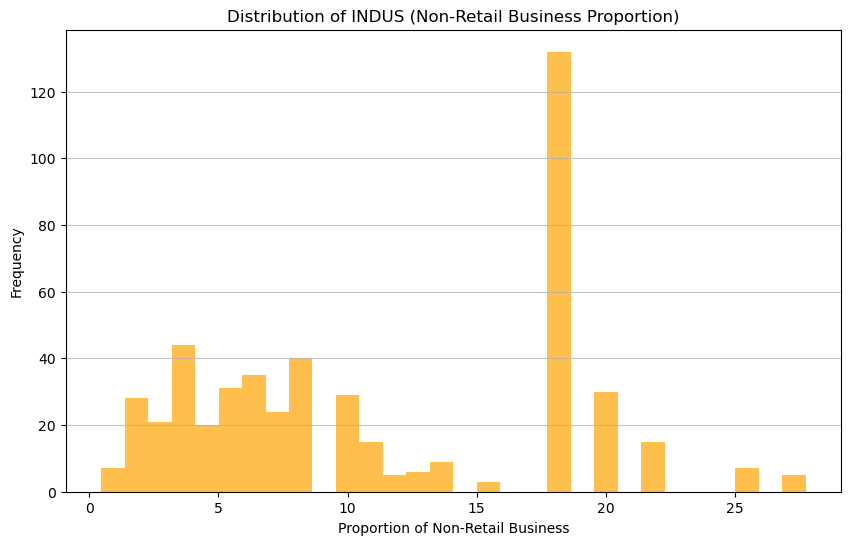

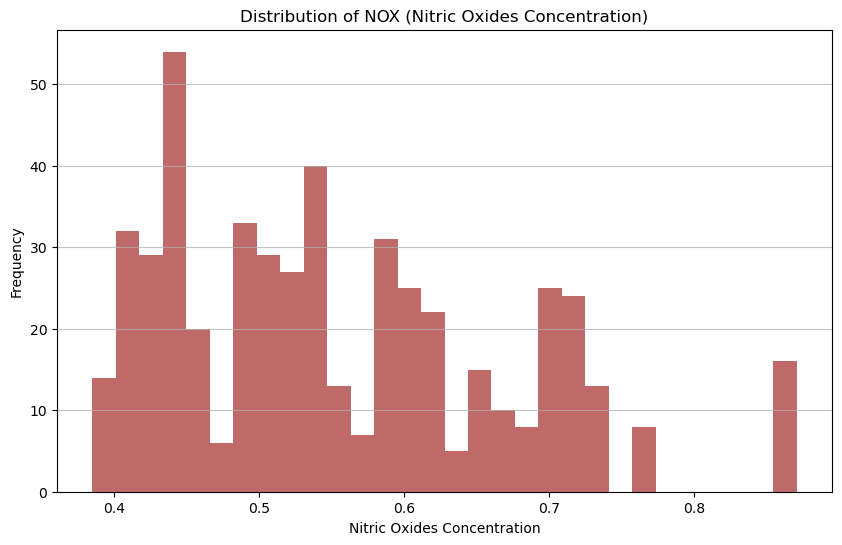

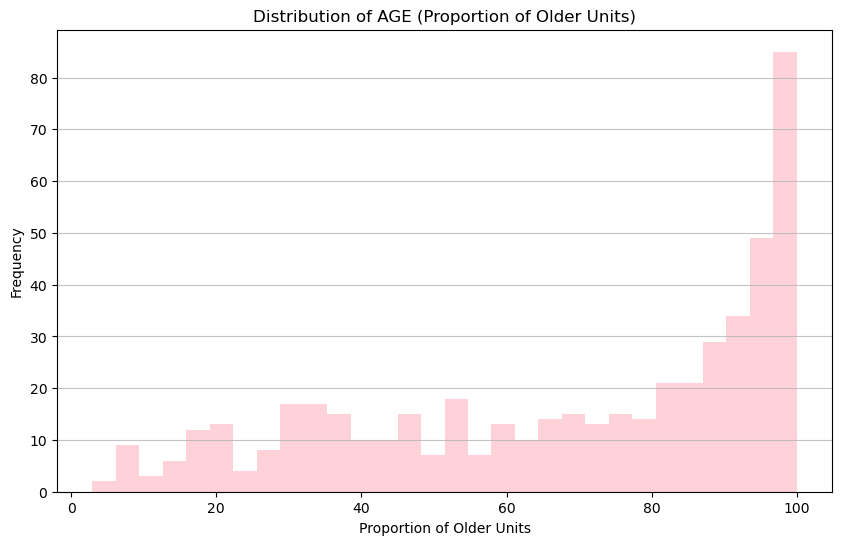

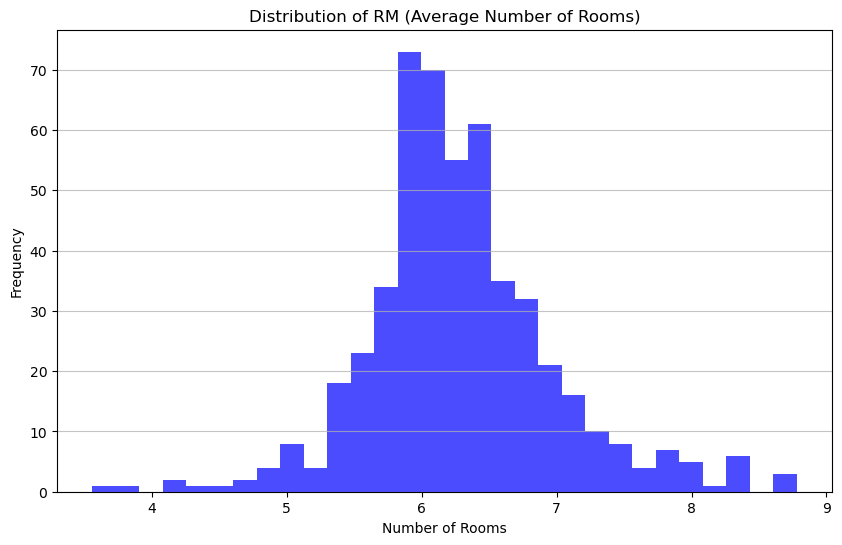

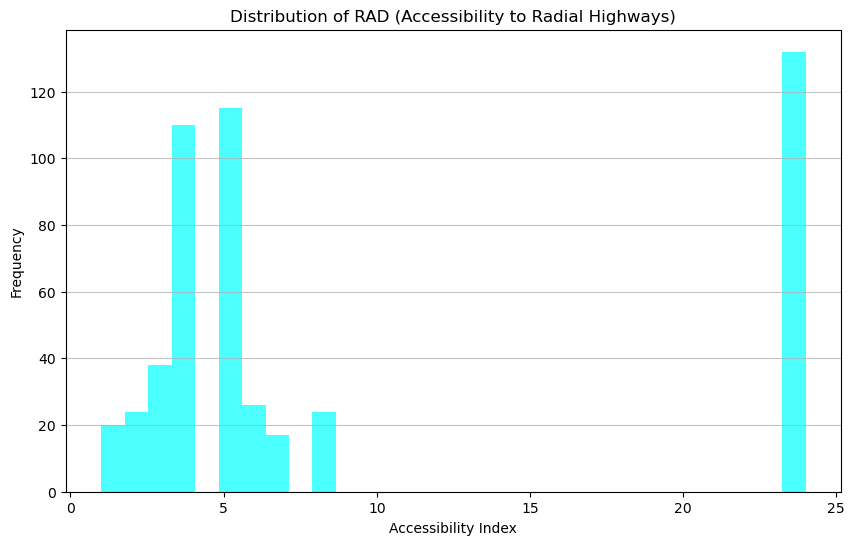

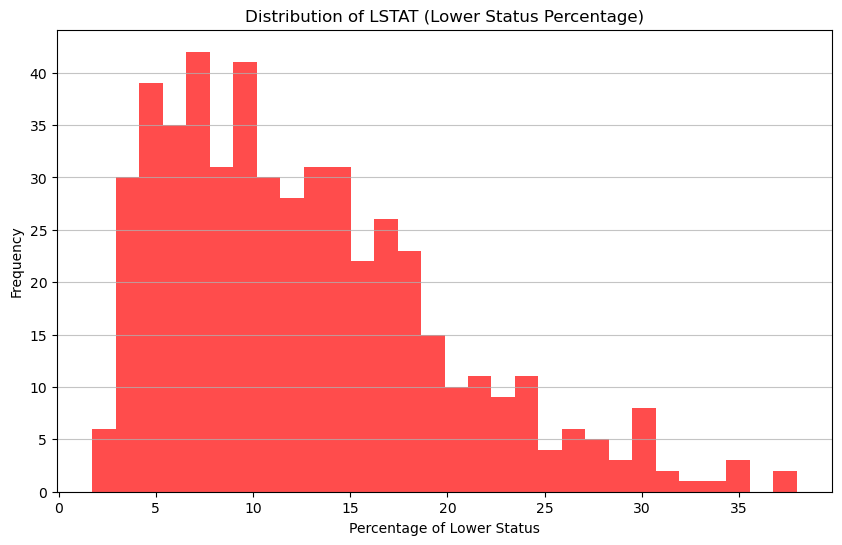

In [5]:
# Plot histograms for key features
#CRIM 
plt.figure(figsize=(10, 6))
plt.hist(df['CRIM'], bins=30, color='purple', alpha=0.7)
plt.title('Distribution of CRIM (Per Capita Crime Rate)')
plt.xlabel('Crime Rate')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()
#ZN - proportion of residential land zoned for lots over 25,000 sq. ft.
plt.figure(figsize=(10, 6)) 
plt.hist(df['ZN'], bins=30, color='green', alpha=0.7)
plt.title('Distribution of ZN (Residential Land Proportion)')
plt.xlabel('Proportion of Residential Land')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()
# INDUS - proportion of non-retail business acres per town
plt.figure(figsize=(10, 6))
plt.hist(df['INDUS'], bins=30, color='orange', alpha=0.7)
plt.title('Distribution of INDUS (Non-Retail Business Proportion)')
plt.xlabel('Proportion of Non-Retail Business')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

# NOX - nitric oxides concentration (parts per 10 million)
plt.figure(figsize=(10, 6))
plt.hist(df['NOX'], bins=30, color='brown', alpha=0.7)
plt.title('Distribution of NOX (Nitric Oxides Concentration)')
plt.xlabel('Nitric Oxides Concentration')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()
# AGE - proportion of owner-occupied units built prior to 1940
plt.figure(figsize=(10, 6))
plt.hist(df['AGE'], bins=30, color='pink', alpha=0.7)
plt.title('Distribution of AGE (Proportion of Older Units)')
plt.xlabel('Proportion of Older Units')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

# RM - average number of rooms per dwelling
plt.figure(figsize=(10, 6))     
plt.hist(df['RM'], bins=30, color='blue', alpha=0.7)
plt.title('Distribution of RM (Average Number of Rooms)')
plt.xlabel('Number of Rooms')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

#RAD - index of accessibility to radial highways
plt.figure(figsize=(10, 6))
plt.hist(df['RAD'], bins=30, color='cyan', alpha=0.7)
plt.title('Distribution of RAD (Accessibility to Radial Highways)')
plt.xlabel('Accessibility Index')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

# LSTAT - percentage of lower status of the population
plt.figure(figsize=(10, 6))
plt.hist(df['LSTAT'], bins=30, color='red', alpha=0.7)
plt.title('Distribution of LSTAT (Lower Status Percentage)')
plt.xlabel('Percentage of Lower Status')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()



#"CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM",
# "AGE", "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"



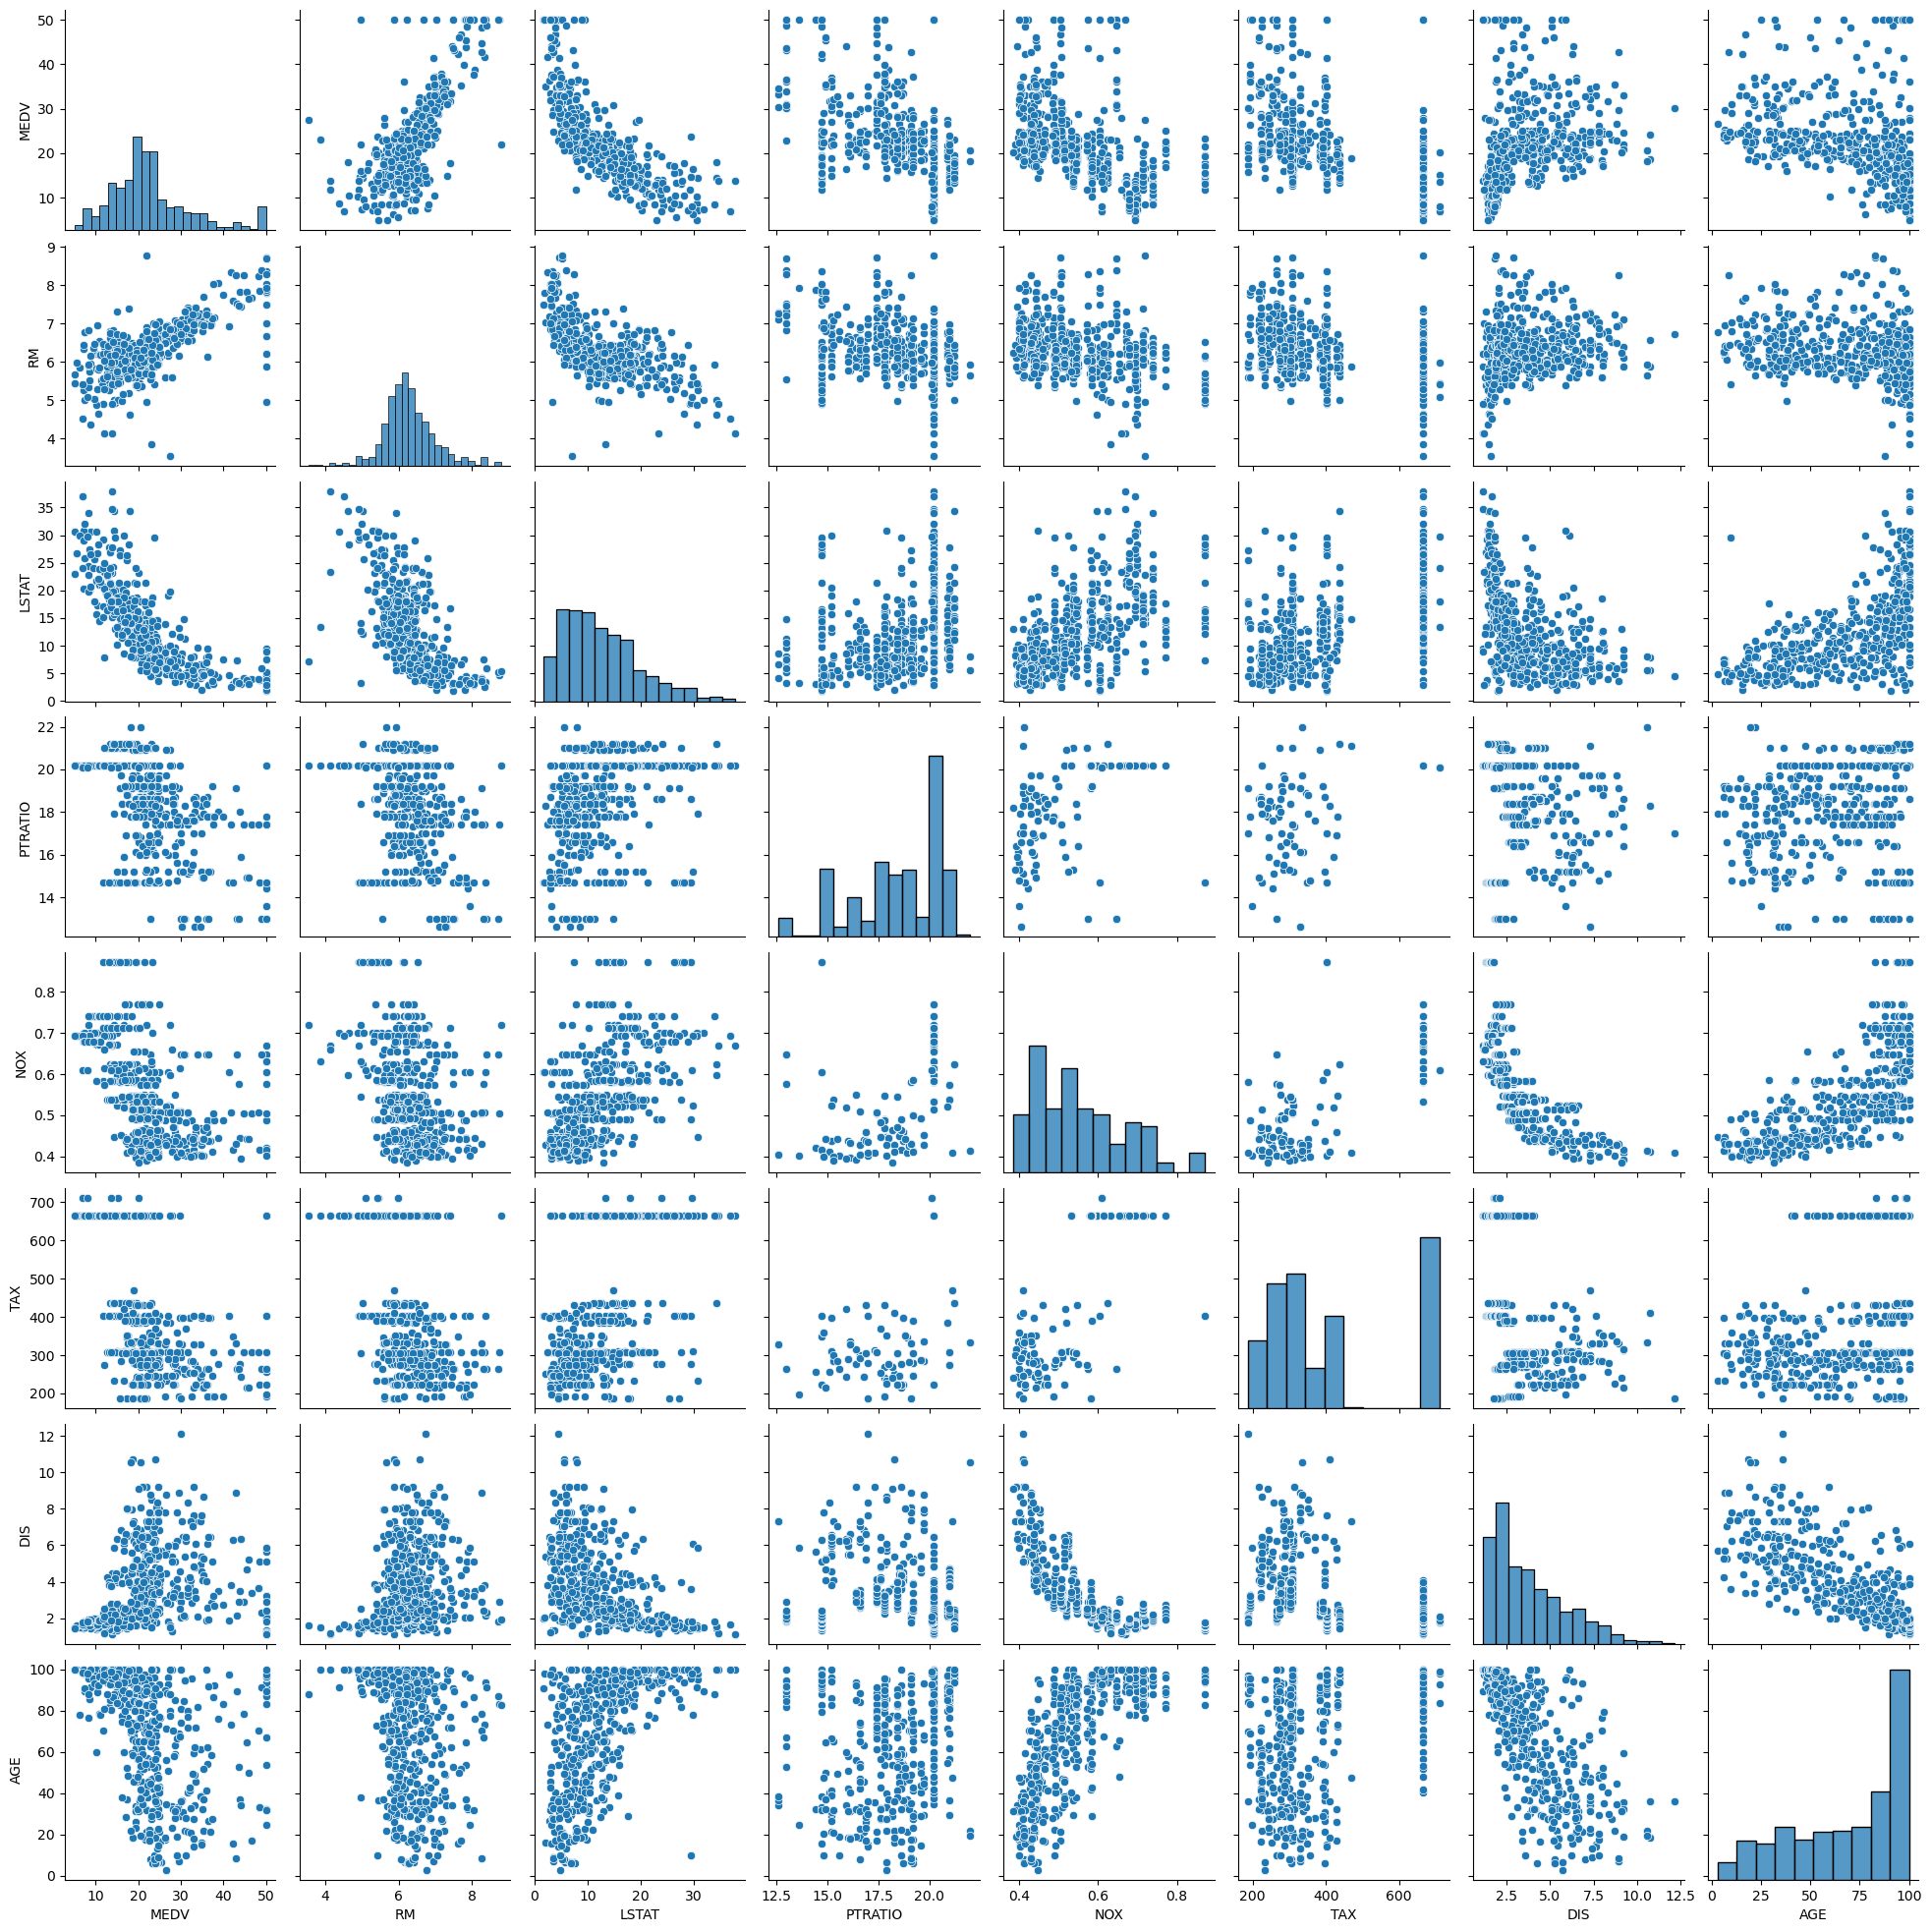

In [6]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Supón que ya tienes el DataFrame cargado como df
selected_cols = ['MEDV', 'RM', 'LSTAT', 'PTRATIO', 'NOX', 'TAX', 'DIS', 'AGE']

sns.pairplot(df[selected_cols])
plt.show()


## Scatter Plots
Visualize relationships between features and the target variable using scatter plots.

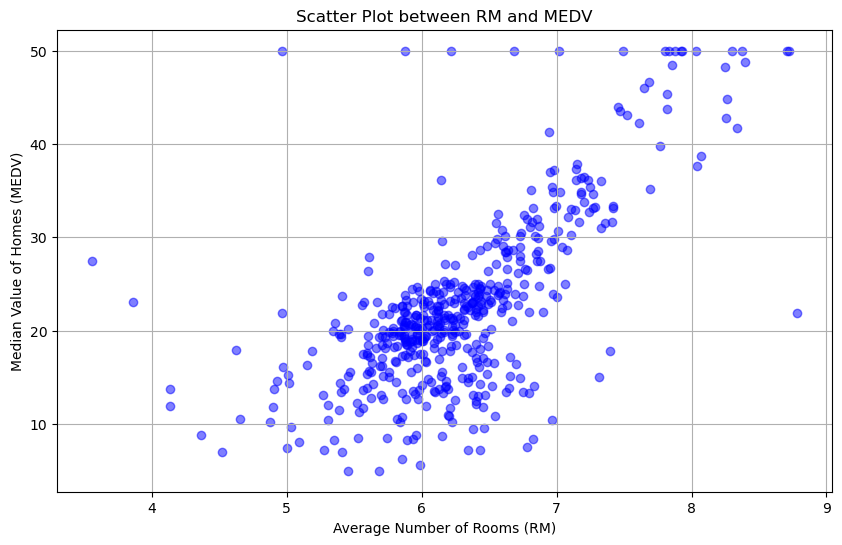

In [7]:
# Scatter plot between RM and MEDV
plt.figure(figsize=(10, 6))
plt.scatter(df['RM'], df['MEDV'], color='blue', alpha=0.5)
plt.title('Scatter Plot between RM and MEDV')
plt.xlabel('Average Number of Rooms (RM)')
plt.ylabel('Median Value of Homes (MEDV)')
plt.grid()
plt.show()

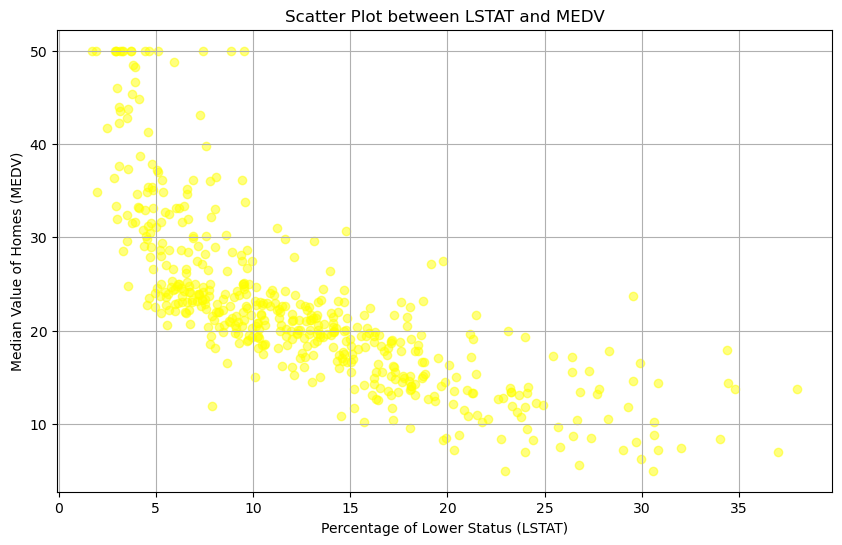

In [8]:
# Scatter plot between LSTAT and MEDV
plt.figure(figsize=(10, 6))
plt.scatter(df['LSTAT'], df['MEDV'], color='yellow', alpha=0.5)
plt.title('Scatter Plot between LSTAT and MEDV')
plt.xlabel('Percentage of Lower Status (LSTAT)')
plt.ylabel('Median Value of Homes (MEDV)')
plt.grid()
plt.show()

# Step 4: Data Preprocessing
- Handle any missing values in the dataset by filling them with the mean of their respective columns


In [9]:
# Fill missing values with the mean of their respective columns
print(df.isnull().sum())  # Check for missing values
print(df['RM'].min()) # Check RM min and max
print(df['RM'].max())

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
LSTAT      0
MEDV       0
dtype: int64
3.561
8.78


# Step 5: Feature Engineering
- Create a new feature called 'PRICE_PER_ROOM' to capture the relationship between the price of the house and the number of rooms. 
    - NOTE: mind that we might be dividing and some values might be zero. You can solve this potential issue here, or prevent it when cleaning the data.
- Separate the features (X) from the target variable (y).
    - The features for training (X)
    - Target variable for testing (y). This is the variable you are aiming to predict.
- Normalize the training data

In [10]:
# Create a new feature 'PRICE_PER_ROOM', handling cases where RM is zero
# Crear 'PRICE_PER_ROOM' evitando división por cero
df['PRICE_PER_ROOM'] = df['MEDV'] / df['RM'].replace(0, np.nan)  # Reemplaza 0 con NaN para evitar división por cero
df['PRICE_PER_ROOM'].fillna(0, inplace=True)  # Rellena NaN con 0, pero no hay NANs
df.head()

/tmp/ipykernel_28950/54858506.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['PRICE_PER_ROOM'].fillna(0, inplace=True)  # Rellena NaN con 0, pero no hay NANs


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV,PRICE_PER_ROOM
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,4.98,24.0,3.650190
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,9.14,21.6,3.363962
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,4.03,34.7,4.829506
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,2.94,33.4,4.772792
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,5.33,36.2,5.065062


In [11]:
# Initialize MinMaxScaler and normalize the data
from sklearn.preprocessing import MinMaxScaler

# 1. Separar X e y (correcto)
X = df.drop('MEDV', axis=1) 
y = df['MEDV']

# 2. Crear scaler y transformar (manteniendo columnas)
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)  # Convertir a DataFrame

# 3. Mostrar primeras filas
print(X_scaled.head())

       CRIM    ZN     INDUS  CHAS       NOX        RM       AGE       DIS  \
0  0.000000  0.18  0.067815   0.0  0.314815  0.577505  0.641607  0.269203   
1  0.000236  0.00  0.242302   0.0  0.172840  0.547998  0.782698  0.348962   
2  0.000236  0.00  0.242302   0.0  0.172840  0.694386  0.599382  0.348962   
3  0.000293  0.00  0.063050   0.0  0.150206  0.658555  0.441813  0.448545   
4  0.000705  0.00  0.063050   0.0  0.150206  0.687105  0.528321  0.448545   

        RAD       TAX   PTRATIO     LSTAT  PRICE_PER_ROOM  
0  0.000000  0.208015  0.287234  0.089680        0.301766  
1  0.043478  0.104962  0.553191  0.204470        0.270588  
2  0.043478  0.104962  0.553191  0.063466        0.430224  
3  0.086957  0.066794  0.648936  0.033389        0.424046  
4  0.086957  0.066794  0.648936  0.099338        0.455882  


# Step 6: Splitting the Data
Split the data into training and testing sets using an 80-20 split to evaluate the model's performance on unseen data.

In [12]:
# Split the data into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Step 7: Model Training
- Train a Linear Regression model on the training data
- You can use LinearRegression from sklearn and the fit method
    - model.fit(...)

In [13]:
# Initialize the Linear Regression model from sklearn
model = LinearRegression()
model.fit(X_train, y_train)
# your code here...

LinearRegression()

# Step 8: Model Evaluation and Cross-validation 
- Evaluate the trained model on the test set using MAE, MSE, and R^2 score.
- Use 5-fold cross-validation to evaluate the model's performance.


In [26]:
# Make predictions on the test set
model_pred = model.predict(X_test)

# MAE evaluate
mae = mean_absolute_error(y_test, model_pred)
print(f'Mean Absolute ERROR (MAE) is: {mae}')

# MSE evaluate
mse =  mean_squared_error(y_test, model_pred)
print(f'Mean Squared Error (MSE) is: {mse}')

# R2 Score
r2 = r2_score(y_test, model_pred)
print(f'R2 Score is: {r2}')

Mean Absolute ERROR (MAE) is: 0.6489199116427807
Mean Squared Error (MSE) is: 1.5034609548725173
R2 Score is: 0.9794983854632777


In [15]:
# Use 5-fold cross-validation to evaluate the model's performance

# your code here...

# Step 9: Serialization
- Serialize the trained model using Pickle and save it to a file.
- Serialize the scaler you have used (if any)
- Serializing (or saving) the scaler and the model is important for several reasons:

    - Scaler: When you normalize your data during model training, you use specific parameters (like min and max values for MinMaxScaler or mean and standard deviation for StandardScaler). To ensure that your data is transformed in the same way during prediction, you need to save the scaler used during training. Without this, you might end up using different scaling parameters, leading to inconsistent results.

    - Model: The trained model contains learned parameters (like coefficients in a linear regression model). Saving the model allows you to reuse these parameters for making predictions on new data without retraining the model each time.


In [16]:
# Serialize the trained model using Pickle (use the name linear_regression_model.pkl)

# your code here...

# Serialize the scaler using Pickle (use the name scaler.pkl)

# your code here...

# Step 10: Creating an API using FastAPI
- Create a FastAPI application to serve the model and make predictions based on input features. Implement a '/predict' endpoint that accepts a POST request with input features and returns the predicted house price.
- As you must run the API code from a dedicated python file, we suggest to put the code in the api.py file (which has been already created for you)
    - This file uses the .pkl models serialized before
    - This API assumes the data model defined by the HouseData class, using the columns from the training data.

# Step 11: Test the API

- This code snippet demonstrates how to test a FastAPI prediction endpoint by sending different sets of input features and observing the model's responses. By using the `requests` library to make POST requests, you can simulate real-world usage of the API, providing various data points to evaluate the model's predictions. 

- This approach allows you to test the importance and influence of each feature on the predicted house prices, helping to understand how different input variables affect the model's output. This can be particularly useful for feature importance analysis and model validation.

- Play with different values on each data point and generate new ones to test the importance of each feature on the resultant predictions.

to start the api : ```uvicorn nombre_del_archivo:app ```

In [17]:
import requests

# URL for the prediction endpoint
url = "http://localhost:8000/predict"

data_1 = {
    "CRIM": 0.00632,
    "ZN": 18.0,
    "INDUS": 2.31,
    "CHAS": 0.0,
    "NOX": 0.538,
    "RM": 6.575,
    "AGE": 65.2,
    "DIS": 4.0900,
    "RAD": 1.0,
    "TAX": 296.0,
    "PTRATIO": 15.3,
    "B": 396.90,
    "LSTAT": 4.98,
    "PRICE_PER_ROOM": 3.65019
}

# your code here...


# Additional Steps:
- Experiment with the input values and try to explore which are the most relevant features for the model
- Experiment with Different Models: Compare the performance of different machine learning models like Decision Tree and Random Forest.
- Advanced Feature Engineering: Implement more advanced feature engineering techniques, such as polynomial features or interaction terms.



The following code retrieves and visualizes the feature importances from a trained linear regression model by extracting the model coefficients and corresponding feature names, sorting them by their absolute values, and displaying the results in a horizontal bar plot. This helps in understanding which features have the most significant impact on the model's predictions. 

           Feature  Importance
12  PRICE_PER_ROOM   59.387698
5               RM   23.880786
11           LSTAT    2.751655
0             CRIM    1.752635
8              RAD   -0.882744
7              DIS   -0.487105
10         PTRATIO   -0.443730
6              AGE   -0.381965
4              NOX    0.242752
9              TAX    0.157822
2            INDUS   -0.086487
3             CHAS    0.067547
1               ZN    0.039447


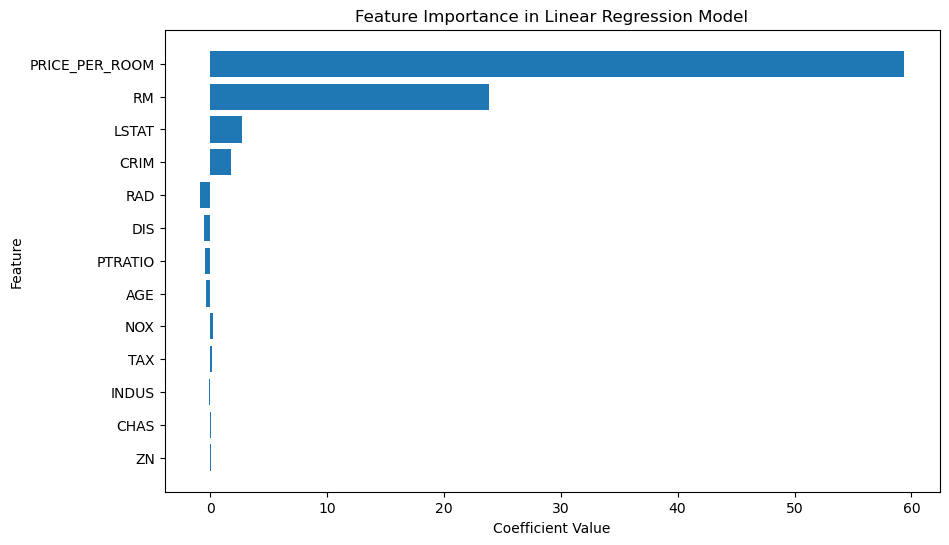

In [18]:
import matplotlib.pyplot as plt

# Assuming model is already trained and X_train is available

# Get the feature names
feature_names = X_train.columns

# Get the model coefficients
coefficients = model.coef_

# Create a DataFrame to hold feature names and their corresponding coefficients
feature_importance = pd.DataFrame({'Feature': feature_names, 'Importance': coefficients})

# Sort the DataFrame by the absolute value of the coefficients
feature_importance['Absolute_Importance'] = feature_importance['Importance'].abs()
feature_importance = feature_importance.sort_values(by='Absolute_Importance', ascending=False)

# Print feature importances
print(feature_importance[['Feature', 'Importance']])

# Plot feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.title('Feature Importance in Linear Regression Model')
plt.gca().invert_yaxis()
plt.show()
